# 14 · 움직이는 장애물을 rollout에 넣기 — 정지 가정과 등속 예측

> 사람이 움직이면 rollout의 미래 30칸마다 사람이 어디에 있을지 정해야 한다. 그 규칙(예측)에 따라 로봇이 언제, 얼마나 피하는지가 달라진다.

| | |
|---|---|
| **이 노트의 질문** | 사람이 움직이면, 미래 30칸의 각 칸에서 사람을 어디에 두고 비용을 계산하는가 |
| **최종 목표** | 정지 가정과 등속 예측의 차이, 그리고 예측이 틀렸을 때 로봇이 어떻게 움직이는지 설명할 수 있다 |
| **연구의 어느 결정과 연결되는가** | 사람 예측 방식 결정: 정지 / 분절 등속 / 관절 등속 |
| **이 노트에서 바꾸는 요인** | 사람의 움직임과 예측 규칙. 질량은 쓰지 않는다(모든 분절에 같은 η = 0.10 m) |

**지금 위치:** 01~13 기초·MPPI·프로젝트 → **14 움직이는 사람** → 15 η와 w → 16 방향별 질량 → 17 ESS → 18 비용 불연속과 떨림 → 19 필요 이격 거리 → 20 안전 필터 → 21 지연 → 22 cuRobo 확인

**필요한 것:** [04](04_mpc.ipynb) 매 스텝 다시 계획, [05](05_mppi_core.ipynb) MPPI 갱신, [06](06_mppi_obstacles.ipynb) η 장애물 비용과 warm start · **예상 시간:** 40분

## 복습 퀴즈

<details><summary>1. η = 0.10 m, w = 100일 때 간격 0.05 m인 칸 하나의 비용은? (08의 식: 0 ≤ 간격 < η이면 w(η−간격)²/(2η))</summary>

100 × 0.05² / 0.2 = **1.25**
</details>

<details><summary>2. Δt = 0.05 s, T = 30이면 rollout은 몇 초 앞까지 보는가?</summary>

30 × 0.05 = **1.5 s**
</details>

<details><summary>3. 06의 warm start에서 다음 스텝으로 넘길 때 평균 입력열 μ에 무엇을 하는가? (a) 0으로 초기화 (b) 한 칸 당긴다 (c) 그대로 둔다</summary>

**(b)** 한 칸 당기고 마지막 칸은 반복한다.
</details>

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # 노트 폴더 (common14 패키지)
import numpy as np
from common14 import *
from common14 import scene as S
plt = setup_plot()
print('시작 %s → 목표 %s, 로봇 반지름 %.2f m' % (S.START, S.GOAL, S.ROBOT_R))
print('MPPI: K=%d, T=%d (%.1f s), 스텝당 갱신 %d회, σ=%.1f, β=%.1f, 균일 η=%.2f m, w=%.0f'
      % (S.K, S.T, S.T * S.DT, S.N_ITERS, S.SIGMA, S.BETA, S.ETA0, S.W_HUMAN))

시작 [0. 0.] → 목표 [2. 0.], 로봇 반지름 0.05 m
MPPI: K=400, T=30 (1.5 s), 스텝당 갱신 5회, σ=2.0, β=1.0, 균일 η=0.10 m, w=100


## 0. 14~21의 공통 장면

14~21 내내 같은 장면을 쓴다. 평면 위의 **2D 점 로봇**(05·06과 같은 가속도 입력, 같은 MPPI)이 **평면 사람**을 지나 목표로 간다. 평면 사람은 위에서 내려다본 모습으로, 몸통(원) 하나와 팔(캡슐) 하나로 되어 있다. 기준 자세에서 사람은 로봇 경로(y = 0) 위에 서서 팔을 로봇 쪽으로 뻗고 있다.

수치와 그 이유는 [common14/README.md](common14/README.md)에 정리했다. 분절별 질량은 15부터 쓴다.

사람이 서 있을 때: 도달 2.40 s, 최소 이격 0.103 m, 지나간 쪽 y 최대 +0.31 / 최소 -0.03 m


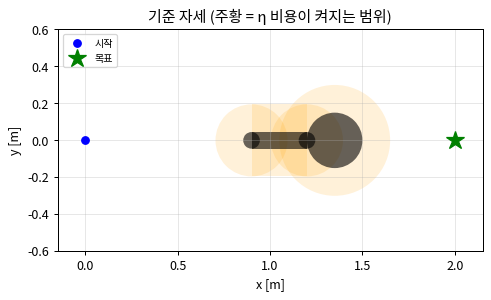

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.2))
draw_scene(ax, eta=S.ETA0)
ax.legend(fontsize=8, loc='upper left'); ax.set_title('기준 자세 (주황 = η 비용이 켜지는 범위)')
plt.show()

r0 = run_mpc(static_person, seed=0)
print('사람이 서 있을 때: 도달 %.2f s, 최소 이격 %.3f m, 지나간 쪽 y 최대 %+.2f / 최소 %+.2f m'
      % (arrival_time(r0['traj']), min_clearance(r0['traj'], r0['person']), r0['traj'][:, 1].max(), r0['traj'][:, 1].min()))

사람이 서 있으면 로봇은 사람을 돌아 목표에 간다. 최소 이격은 η(0.10 m) 근처다. 06에서 본 것처럼 η 안으로 들어오면 비용이 생기기 시작하므로, 로봇은 대략 그 경계를 따라 지나간다. 위·아래 모양이 대칭이라 어느 쪽으로 돌지는 seed에 따라 달라진다.

## 1. 문제 — 사람이 움직이면 30칸 각각에서 사람은 어디에?

### 문제
05~13에서 장애물은 움직이지 않았다. 그래서 rollout의 30칸 모두에서 장애물을 **같은 자리**에 두고 비용을 계산하면 됐다.

사람이 움직이면 사정이 다르다. 비용은 "칸 t의 로봇 위치"와 "칸 t의 사람 위치"를 비교해야 한다. 칸 t는 지금부터 $\tau_t = (t+1)\,\Delta t$초 뒤의 미래인데, 그때 사람이 어디 있을지는 아직 모른다.

### 아이디어
지금 관측한 사람 정보로 미래 각 칸의 사람 위치를 정하는 규칙을 **예측**(prediction)이라고 부른다. 비용 함수는 예측한 위치를 칸마다 하나씩 받는다. 공통 모듈의 사람 비용 `human_cost_uniform(Pf, offsets)`이 바로 그렇게 생겼다.
- `Pf`: 후보 K개의 미래 위치 `[K, 30, 2]`
- `offsets`: 칸마다의 사람 위치(기준 자세에서 얼마나 옮겼는지) `[30, 2]`

칸 t의 후보 위치는 칸 t의 사람과만 비교된다.

In [3]:
rng = np.random.default_rng(0)
U = rng.normal(0, 2, size=(S.K, S.T, 2))
P, V = rollout(S.START, np.zeros(2), U)
offsets_static = np.zeros((S.T, 2))                                   # 30칸 모두 기준 자세
offsets_moving = np.stack([[0.0, 0.6 - 0.5 * (t + 1) * S.DT] for t in range(S.T)])   # 칸마다 다른 위치
print('후보 미래 위치 Pf:', P[:, 1:].shape, ' 사람 위치 offsets:', offsets_static.shape)
print('사람 비용 모양:', human_cost_uniform(P[:, 1:], offsets_static).shape, '(후보 × 칸)')
U_straight = np.tile([1.8, 0.0], (S.T, 1))                         # 목표를 향해 곧장 가속하는 후보 하나
P1, _ = rollout(S.START, np.zeros(2), U_straight)
print('곧장 가는 후보의 사람 비용 합: 기준 자세에 서 있는 사람 %.1f, 칸마다 위치가 다른 사람 %.1f'
      % (human_cost_uniform(P1[1:], offsets_static).sum(), human_cost_uniform(P1[1:], offsets_moving).sum()))

후보 미래 위치 Pf: (400, 30, 2)  사람 위치 offsets: (30, 2)
사람 비용 모양: (400, 30) (후보 × 칸)
곧장 가는 후보의 사람 비용 합: 기준 자세에 서 있는 사람 110.9, 칸마다 위치가 다른 사람 79.5


같은 후보라도 사람을 칸마다 어디에 두느냐에 따라 비용이 달라진다. 그러면 MPPI가 고르는 후보도 달라진다.

## 2. 세 가지 예측 규칙

지금 시각에 관측한 사람 위치를 $\mathbf{c}$, 속도를 $\mathbf{v}$라 하자(이 노트에서는 정확히 안다고 가정한다).

| 규칙 | 칸 t의 사람 위치 | 뜻 |
|---|---|---|
| **정지 가정** (static) | $\mathbf{c}$ | 사람이 지금 자리에 그대로 있다고 본다. 05~13의 장애물 처리와 같다 |
| **등속 예측** (constant velocity, CV) | $\mathbf{c} + \mathbf{v}\,\tau_t$ | 지금 속도 그대로 계속 걷는다고 본다 |
| **오라클** (oracle) | 참 미래 위치 | 실제로는 알 수 없다. 비교 기준으로만 쓴다 |

사람 전체가 같은 속도로 평행이동한다고 보는 등속 예측은 연구 설계의 "분절 등속"에 해당한다(분절마다 자기 속도로 등속). 팔이 관절을 중심으로 도는 "관절 등속"은 이 노트에서 다루지 않는다.

**예측해 보기:** 사람이 0.5 m/s로 걷고 있으면, 마지막 칸(τ = 1.5 s)에서 정지 가정의 예측은 실제와 얼마나 어긋날까?

아래는 경로 옆(+0.6 m)에서 −y로 걸어 들어오는 사람을, t = 0.4 s 시점에서 세 규칙으로 예측한 모습이다.

τ = 0.25 s: 정지 가정 오차 0.125 m, 등속 예측 오차 0.000 m
τ = 0.75 s: 정지 가정 오차 0.375 m, 등속 예측 오차 0.000 m
τ = 1.50 s: 정지 가정 오차 0.750 m, 등속 예측 오차 0.000 m


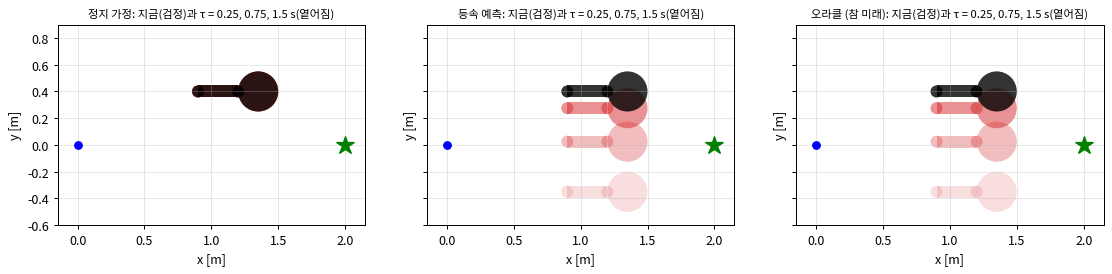

In [4]:
person = crossing()                          # 경로 옆에서 -y로 0.5 m/s, 계속 걸어서 경로를 가로지른다
t_now = 0.4
c, v = person(t_now)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, (name, pred) in zip(axs, [('정지 가정', lambda tau: c), ('등속 예측', lambda tau: c + v * tau),
                                   ('오라클 (참 미래)', lambda tau: person(t_now + tau)[0])]):
    draw_scene(ax, lim=((-0.15, 2.15), (-0.6, 0.9)), show_person=False)
    for tau, a in [(0.25, 0.5), (0.75, 0.3), (1.5, 0.15)]:
        draw_person(ax, pred(tau), alpha=a, color='C3')
    draw_person(ax, c, alpha=0.8, color='k')
    ax.set_title(f'{name}: 지금(검정)과 τ = 0.25, 0.75, 1.5 s(옅어짐)', fontsize=9)
plt.show()
for tau in [0.25, 0.75, 1.5]:
    true = person(t_now + tau)[0]
    print('τ = %.2f s: 정지 가정 오차 %.3f m, 등속 예측 오차 %.3f m' % (tau, np.linalg.norm(c - true), np.linalg.norm(c + v * tau - true)))

**결과 해석:** 사람이 실제로 등속으로 걷고 있으면 등속 예측은 오차가 0이고, 정지 가정의 오차는 속도 × τ만큼(마지막 칸 0.5 × 1.5 = 0.75 m) 커진다. 정지 가정에서는 rollout의 먼 칸일수록 사람이 실제보다 뒤처진 자리에 있다.

**한 문장으로:** 정지 가정의 예측 오차가 rollout의 먼 칸일수록 커지는 이유를 설명해 보자.

## 3. 장면 A — 경로를 가로지르는 사람 (등속)

사람이 경로 옆 0.6 m에서 출발해 0.5 m/s로 경로를 가로질러 걸어간다(t = 1.2 s에 경로 위를 지난다). 로봇은 같은 MPPI로, 예측 규칙만 바꿔서 달린다. 결과가 seed에 따라 달라질 수 있어서 seed 4개로 돌린다.

**예측해 보기:** 정지 가정의 로봇은 처음(t = 0)에 사람이 경로 옆 0.6 m에 있다고 본다. 이 로봇은 언제 피하기 시작할까? 최소 이격은 η(0.10 m)보다 클까, 작을까?

In [5]:
SEEDS = range(4)

def run_all(person, preds=('static', 'cv', 'oracle')):
    out = {}
    for pred in preds:
        out[pred] = [run_mpc(person, predictor=pred, seed=s) for s in SEEDS]
    return out

def summarize(out):
    print('%-7s | %-27s | %-27s | %-27s' % ('예측', '최소 이격 [m] (seed 0~3)', '회피 시작 [s]', '도달 [s]'))
    for pred, runs in out.items():
        mc = [min_clearance(r['traj'], r['person']) for r in runs]
        av = [avoid_start_time(r['traj']) for r in runs]
        ar = [arrival_time(r['traj']) for r in runs]
        print('%-7s | %-27s | %-27s | %-27s' % (pred, ' '.join('%.3f' % x for x in mc), ' '.join(str(x) for x in av), ' '.join(str(x) for x in ar)))

out_A = run_all(crossing())
summarize(out_A)
diff = max(np.abs(a['traj'] - b['traj']).max() for a, b in zip(out_A['cv'], out_A['oracle']))
print('\n등속 예측과 오라클의 궤적 최대 차이: %.1e m' % diff)

예측      | 최소 이격 [m] (seed 0~3)        | 회피 시작 [s]                   | 도달 [s]                     
static  | 0.014 0.019 0.017 0.020     | 0.9 0.85 0.9 0.9            | 2.35 2.1 2.1 2.25          
cv      | 0.088 0.085 0.107 0.105     | 0.2 0.25 0.55 0.45          | 2.4 1.65 1.55 1.45         
oracle  | 0.088 0.085 0.107 0.105     | 0.2 0.25 0.55 0.45          | 2.4 1.65 1.55 1.45         

등속 예측과 오라클의 궤적 최대 차이: 4.4e-16 m


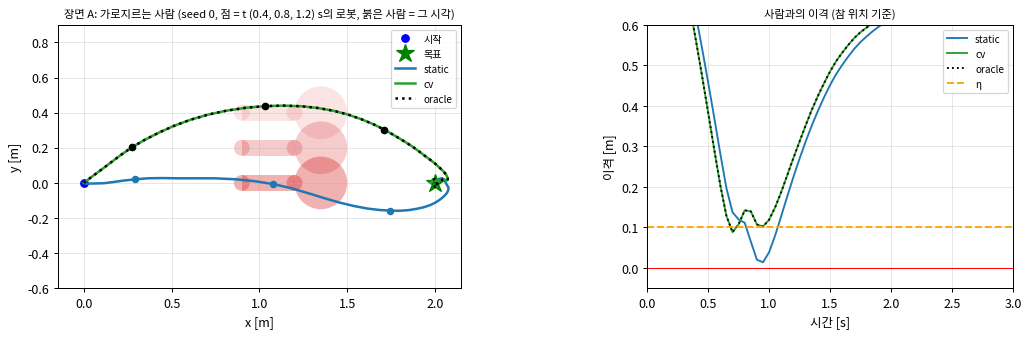

In [6]:
def plot_runs(out, title, seed=0, times=(0.4, 0.8, 1.2)):
    fig, axs = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
    ax = axs[0]
    draw_scene(ax, lim=((-0.15, 2.15), (-0.6, 0.9)), show_person=False)
    r = out['static'][seed]
    for t in times:                                   # 참 사람 위치 몇 장
        draw_person(ax, r['person'][int(round(t / S.DT))], alpha=0.12 + 0.12 * times.index(t), color='C3')
    for pred, col in [('static', 'C0'), ('cv', 'C2'), ('oracle', 'k')]:
        if pred in out:
            tr = out[pred][seed]['traj']
            ax.plot(*tr.T, '-' if pred != 'oracle' else ':', color=col, lw=2, label=pred)
            for t in times:
                ax.plot(*tr[int(round(t / S.DT))], 'o', color=col, ms=5)
    ax.legend(fontsize=8, loc='upper right'); ax.set_title(f'{title} (seed {seed}, 점 = t {times} s의 로봇, 붉은 사람 = 그 시각)', fontsize=9)
    ax = axs[1]
    for pred, col in [('static', 'C0'), ('cv', 'C2'), ('oracle', 'k')]:
        if pred in out:
            r = out[pred][seed]
            ax.plot(np.arange(len(r['traj'])) * S.DT, clearance_series(r['traj'], r['person']), '-' if pred != 'oracle' else ':', color=col, label=pred)
    ax.axhline(S.ETA0, color='orange', ls='--', label='η'); ax.axhline(0, color='r', lw=0.8)
    ax.set_xlim(0, 3); ax.set_ylim(-0.05, 0.6); ax.set_xlabel('시간 [s]'); ax.set_ylabel('이격 [m]'); ax.legend(fontsize=8)
    ax.set_title('사람과의 이격 (참 위치 기준)', fontsize=9)
    plt.show()

plot_runs(out_A, '장면 A: 가로지르는 사람')

**결과 해석** (위 표와 그림의 숫자를 보며)
- **정지 가정**은 늦게 피한다. 처음에는 사람이 경로 옆에 있으니 직진하고, 사람이 실제로 경로에 가까워진 뒤에야 피하기 시작한다. 그때는 이미 가까워서 최소 이격이 η보다 훨씬 작다.
- **등속 예측**은 사람이 1초쯤 뒤 경로를 막을 것을 rollout 안에서 미리 보고 일찍 피한다. 최소 이격이 η 근처로 유지된다.
- 등속 예측과 오라클은 지표가 모두 같고, 궤적 차이도 계산 오차 수준이다(위 출력의 최대 차이). 사람이 실제로 등속으로 걸었으니 두 규칙의 예측 위치가 같고, MPPI의 seed도 같기 때문이다. 두 예측 위치를 계산하는 순서가 달라 생기는 아주 작은 부동소수점 차이만 남는다.
- 피하는 방향(위로 돌아 사람 뒤로 지나가기 / 아래로 앞질러 지나가기)은 seed마다 다르다. 둘 다 사람을 피하는 해다.

정지 가정이 늦는 것은 MPPI가 아니라 **비용에 들어간 미래**가 틀렸기 때문이다. rollout은 1.5 s를 내다보는데, 정지 가정에서는 그 1.5 s 동안 사람이 처음 자리에 계속 있다고 계산한다.

## 4. 정면으로 다가오는 사람에서는?

로봇 쪽(−x)으로 0.5 m/s로 다가오는 사람에서도 같은 차이가 날까?

**예측해 보기:** 이번에는 사람이 처음부터 경로 위에 있다. 정지 가정과 등속 예측의 차이는 장면 A보다 클까, 작을까?

In [7]:
out_F = run_all(frontal(), preds=('static', 'cv'))
summarize(out_F)

예측      | 최소 이격 [m] (seed 0~3)        | 회피 시작 [s]                   | 도달 [s]                     
static  | 0.093 0.085 0.081 0.087     | 0.25 0.25 0.35 0.3          | 2.35 2.1 1.55 2.25         
cv      | 0.098 0.092 0.086 0.095     | 0.2 0.25 0.25 0.2           | 1.5 1.5 1.5 2.25           


**결과 해석:** 차이가 작다. 최소 이격은 네 seed 모두 등속 예측이 몇 mm 크고, 회피 시작은 비슷하다(도달은 등속 예측 쪽이 대체로 빨랐다). 사람이 처음부터 경로 위에 있고 1.5 s 예측 구간 안에 들어와 있어서, 정지 가정으로도 "길이 막혔다"는 사실은 처음부터 보인다. 두 규칙 모두 곧바로 돌아가기 시작한다. 차이는 다가오는 만큼 조금 더 가까워진다는 정도다.

**예측이 크게 중요해지는 조건:** 사람이 예측 구간 안에서 경로를 **새로 막을 때**(장면 A)다. 지금 보이는 자리만으로는 막힘이 드러나지 않기 때문이다.

## 5. 장면 B — 예측이 틀릴 때

이번 사람은 장면 A처럼 경로 쪽으로 걸어오다가 **t = 0.6 s에 방향을 바꿔 되돌아간다**(경로에서 0.3 m 떨어진 곳에서). 결국 경로를 막지 않는다.

**예측해 보기:** t = 0.6 s까지 등속 예측은 "사람이 곧 경로를 막는다"고 계산한다. 등속 예측의 로봇은 어떻게 움직일까? 정지 가정과 오라클은?

In [8]:
out_B = run_all(turn_back())
summarize(out_B)
print()
for pred in ['static', 'cv', 'oracle']:
    ymax = [r['traj'][:, 1].max() for r in out_B[pred]]
    ymin = [r['traj'][:, 1].min() for r in out_B[pred]]
    L = [path_length(r['traj']) for r in out_B[pred]]
    print('%-7s y 최대 %s | y 최소 %s | 경로 길이 %s m' % (pred, ' '.join('%+.2f' % x for x in ymax),
          ' '.join('%+.2f' % x for x in ymin), ' '.join('%.2f' % x for x in L)))

예측      | 최소 이격 [m] (seed 0~3)        | 회피 시작 [s]                   | 도달 [s]                     
static  | 0.236 0.287 0.265 0.260     | None None None None         | 1.45 1.5 1.5 1.45          
cv      | 0.032 0.032 0.359 0.372     | 0.2 0.25 0.55 0.45          | 2.45 2.25 1.5 1.45         
oracle  | 0.220 0.274 0.256 0.254     | None None None None         | 1.45 1.5 1.5 1.45          

static  y 최대 +0.03 +0.03 +0.02 +0.03 | y 최소 -0.03 -0.03 -0.03 -0.04 | 경로 길이 2.32 2.28 2.35 2.36 m
cv      y 최대 +0.84 +0.83 +0.02 +0.03 | y 최소 -0.04 -0.05 -0.15 -0.15 | 경로 길이 3.08 3.09 2.38 2.39 m
oracle  y 최대 +0.04 +0.03 +0.02 +0.03 | y 최소 -0.03 -0.03 -0.03 -0.04 | 경로 길이 2.31 2.28 2.35 2.35 m


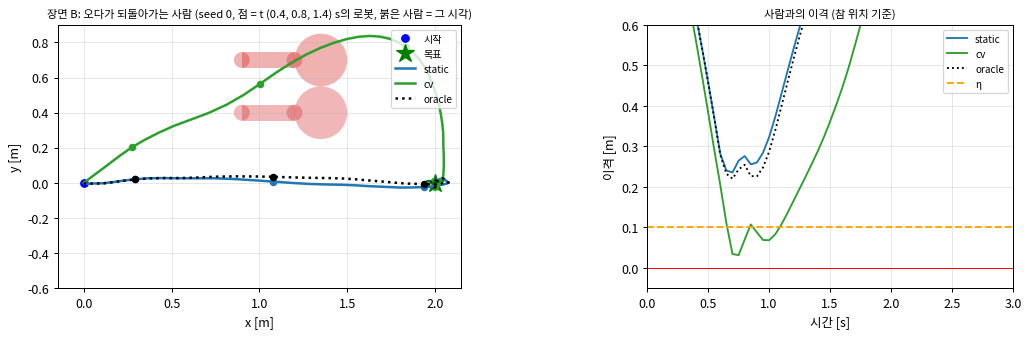

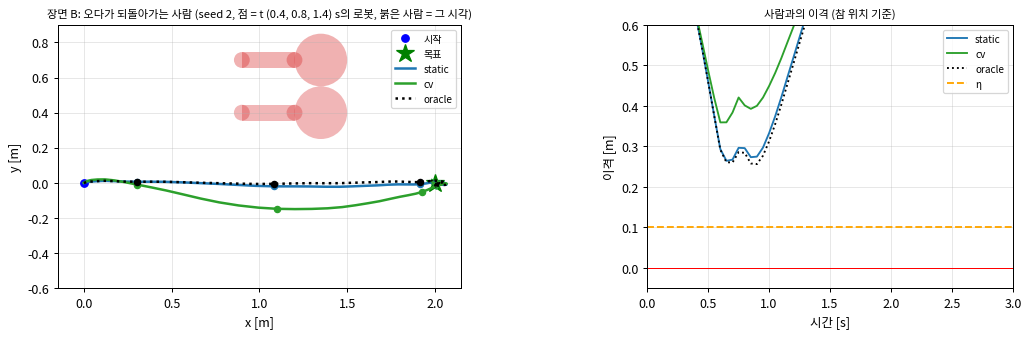

In [9]:
plot_runs(out_B, '장면 B: 오다가 되돌아가는 사람', seed=0, times=(0.4, 0.8, 1.4))
plot_runs(out_B, '장면 B: 오다가 되돌아가는 사람', seed=2, times=(0.4, 0.8, 1.4))

**결과 해석** (표와 두 그림을 보며)
- **정지 가정과 오라클**은 거의 직진한다. 정지 가정은 사람이 아직 경로 옆에 있다고 보고, 오라클은 사람이 되돌아갈 것을 안다. 결과적으로 둘 다 옳은 판단을 했다.
- **등속 예측**은 t = 0.6 s 전까지 "사람이 곧 경로를 막는다"고 계산해서 미리 비킨다. 사람이 되돌아가면 그 회피는 **헛된 것**이 된다. 경로가 길어진다.
- 더 나쁜 경우도 있다. 위쪽(사람이 오던 쪽, 사람 뒤로 지나가기)을 고른 seed에서는 사람이 되돌아오는 방향과 로봇이 비킨 방향이 같아져서, **오히려 사람에게 가까워진다**(최소 이격이 크게 줄어든 seed). 아래쪽을 고른 seed는 조금 돌아가는 정도로 끝난다.

예측이 틀리면 MPPI는 틀린 미래에 대해 최선을 다한다. 비용 함수 입장에서는 그 행동이 맞다. 문제는 비용에 넣은 미래다.

## 6. 정리 — 예측 규칙의 득실

| | 정지 가정 | 등속 예측 |
|---|---|---|
| 사람이 계속 같은 속도로 걸을 때 | 늦게 피한다. 경로를 새로 막는 사람에게 이격이 크게 줄어든다(장면 A) | 오라클과 같다. 미리 피한다 |
| 사람이 처음부터 경로 위에 있을 때 | 차이가 작다(4절) | 차이가 작다 |
| 사람이 방향을 바꿀 때 | 바뀌기 전 자리를 기준으로 판단. 이 장면에서는 직진이 옳았다 | 헛되이 피하고, 비킨 방향이 나쁘면 오히려 가까워진다(장면 B) |
| 예측 오차 | 속도 × τ (먼 칸일수록 큼) | 속도 변화 × τ (방향이 바뀌면 커짐) |

연구의 예측 방식 결정에 쓸 수 있는 관찰은 다음과 같다. 정지 가정은 "가로질러 오는 사람"에 약하고, 등속 예측은 "방향을 바꾸는 사람"에 약하다. 어느 쪽이 나은지는 사람이 실제로 어떻게 움직이는지와 horizon 길이에 달려 있다. 이 노트는 한 장면·seed 4개의 결과이고, 속도는 정확히 안다고 가정했다(실제로는 Kinect 추정 속도에 잡음과 지연이 있다. 지연은 21에서 다룬다).

## 핵심 정리

- 사람이 움직이면 비용 함수는 rollout의 칸마다 다른 사람 위치를 받아야 한다. 그 위치를 정하는 규칙이 **예측**이다.
- **정지 가정**: 모든 칸에 지금 위치. 오차 = 속도 × τ.
- **등속 예측**: 지금 위치 + 속도 × τ. 사람이 등속이면 오라클과 같다.
- 예측이 크게 중요해지는 것은 사람이 예측 구간 안에서 경로를 **새로** 막을 때다. 예측이 틀리면 MPPI는 틀린 미래를 정확히 따른다.

## 확인 문제

<details><summary>1. (계산) 지금 사람 위치 (0, 0.4) m, 속도 (0, −0.5) m/s. Δt = 0.05 s일 때 칸 t = 19 (τ = 1.0 s)에서 등속 예측의 위치는? 정지 가정의 위치는?</summary>

등속: (0, 0.4 − 0.5 × 1.0) = **(0, −0.1) m**. 정지: **(0, 0.4) m**.
</details>

<details><summary>2. (계산) 장면 B의 사람(t = 0.6 s까지 −y로 0.5 m/s, 그 뒤 +y로 0.5 m/s)을 t = 0에서 등속 예측하면, 마지막 칸(τ = 1.5 s)의 예측 오차는 몇 m인가?</summary>

예측: y₀ − 0.5 × 1.5 = y₀ − 0.75. 참: y₀ − 0.5 × 0.6 + 0.5 × 0.9 = y₀ + 0.15. 오차 **0.90 m**.
</details>

<details><summary>3. (보기) 장면 A에서 최소 이격이 가장 작았던 예측 규칙은? (a) 정지 가정 (b) 등속 예측 (c) 오라클</summary>

**(a)** 정지 가정. 사람이 경로에 다가온 뒤에야 피하기 시작했다.
</details>

<details><summary>4. (보기) 장면 A에서 등속 예측과 오라클의 결과(지표)가 같았다. 이유를 모두 고르시오. (a) 사람이 실제로 등속으로 걸었다 (b) 두 실행의 MPPI seed가 같았다 (c) η가 같았다</summary>

**(a), (b)**. (a) 때문에 칸마다 예측 위치가 같고, (b) 때문에 샘플이 같다. (c)는 세 규칙 모두 같아서 차이를 설명하지 못한다.
</details>

<details><summary>5. (보기) 정면으로 다가오는 사람(4절)에서 두 규칙의 차이가 작았던 이유는? (a) 사람이 느려서 (b) 사람이 처음부터 경로 위에 있어 정지 가정으로도 막힘이 보였다 (c) MPPI 후보가 적어서</summary>

**(b)**
</details>

## 다음 노트

**[15 · η와 w](15_eta_vs_weight.ipynb)**: 이제 사람의 질량을 비용에 넣는다. 질량을 "비용이 켜지는 거리 η"로 넣는 것과 "비용의 세기 w"로 넣는 것이 이격을 어떻게 다르게 바꾸는지 본다. 15부터는 사람이 서 있는 기준 장면으로 돌아간다.